This optional task extends the next-step risk to the final outcome of the **current individual possession**. It is separate from the core pressure analysis and the team-possession retrospective summary. The composition example uses synthetic probabilities; an optional second example loads an existing research booster on a synthetic tracking state. No new model is trained here. **design choice**

## Target and composition

Let $c(s)$ be the probability of terminal individual-possession failure, conditional on selecting and successfully completing the current drive. The existing booster predicts **success** ($y=1$), so $c=1-P(y=1)$. A successful pass ends this individual's possession without failure. With pass probability $p$, drive loss $d$ and expected pass failure $f$, the optional composition is

$$Q(s)=p f+(1-p)[d+(1-d)c].$$

The core local hazard is $h(s)=p f+(1-p)d$. Thus $Q-h=(1-p)(1-d)c$: continuation is counted only after a successful drive. This is not a team-possession xLoss after a completed pass. **own derivation**


Local hazard: 0.14
Terminal loss with c=0.3: 0.30200000000000005


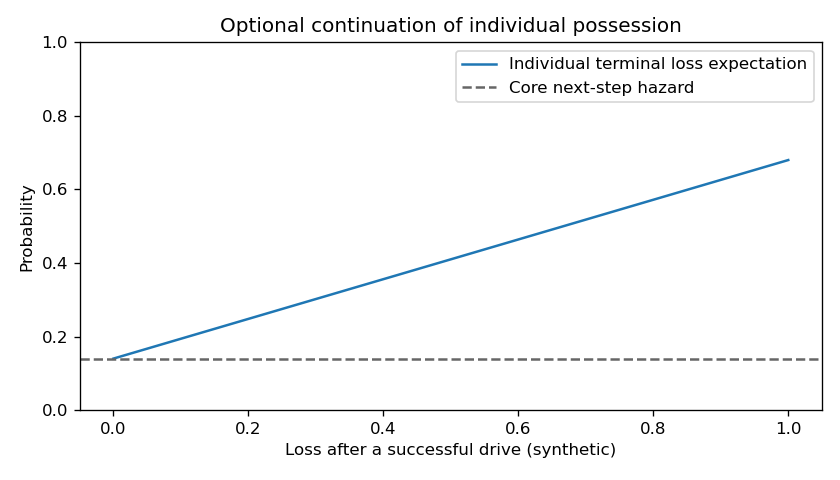

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PRESS.extras import compose_individual_xloss

# Illustrative probabilities, not learned predictions or performance results.
p_pass, drive_loss, pass_failure = 0.4, 0.1, 0.2
residual_loss = np.linspace(0, 1, 101)
hazard = p_pass * pass_failure + (1-p_pass) * drive_loss
xloss = compose_individual_xloss(p_pass=p_pass, drive_loss=drive_loss,
    pass_failure=pass_failure, residual_loss=residual_loss)
assert np.isclose(xloss[0], hazard)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(residual_loss, xloss, label="Individual terminal loss expectation")
ax.axhline(hazard, color="0.4", linestyle="--", label="Core next-step hazard")
ax.set(xlabel="Loss after a successful drive (synthetic)", ylabel="Probability",
       ylim=(0, 1), title="Optional continuation of individual possession")
ax.legend(); fig.tight_layout()
out = Path("figures/vignette_12_residual_risk.png")
out.parent.mkdir(exist_ok=True)
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))
print("Local hazard:", hazard)
print("Terminal loss with c=0.3:", compose_individual_xloss(
    p_pass=p_pass, drive_loss=drive_loss, pass_failure=pass_failure, residual_loss=0.3))


## Existing training experiment

Source: `skillcorner-analysis/scripts/training/choice_model/build_final_dataset.py` and `scripts/training/residual_risk/`. The historical experiment kept successful drive rows whose individual possession ended with `pass`, `possession_loss`, or `foul_suffered`. Terminal labels are **success=1** for a completed pass or foul suffered and **success=0** for possession loss or a failed terminal pass. Shot/clearance endings were outside that historical training subset. The active v2 builder now restricts to canonical successful drives observed for one full second, adds clearance as final individual loss, and excludes short tails. Shot-ending possessions remain outside this extra. The existing artifacts have not been refitted to this convention. Lookup keys include match ID because possession IDs are match-local. **processing boundary**

Features are the 12 physical action-selection summaries, standardized start/previous-action categories, and `time_since_start` at **frame_start**, without shifting to the observed end of the successful drive. `ball_drive_prob` means drive **success**, as in action selection. Elapsed time is present in this extra and remains absent from core action selection. The conditional survival target does not license using observed future tracking at inference. **model scope**

Saved variants include baseline, tuning, v2 and `v3_monotone_only`. The v3 script imposes nondecreasing success with elapsed time; that is a modeling assumption, not a football law. The artifacts are cross-validation fold models; no final production residual booster was found. They remain external. Their existence establishes an implemented experiment, not validated equivalence to SkillCorner xLoss or a selected benchmark winner.

## Optional inference with an existing fold artifact

Set `PRESS_RESIDUAL_MODEL` to a chosen JSON file before executing this notebook or its rebuild. For example, use the sibling path `skillcorner-analysis/results/residual_risk/residual_risk_results_v3_monotone_only/fold_1_model.json`. The caller selects the variant and fold explicitly. In this example inputs come from **synthetic tracking**, and coarse grids change the features; its output is an integration illustration, not a performance estimate. Without the variable, the external inference cell reports that it was skipped; the composition example remains fully executable.


In [5]:
import os
import pandas as pd
import xgboost as xgb
from PRESS import PRESS
from PRESS.datasets import load_demo_match
from PRESS.extras import BCOS
from PRESS.utils.action_selection import build_action_selection_features, get_action_selection_booster

model_path = os.environ.get("PRESS_RESIDUAL_MODEL")
if model_path:
    tracking, possessions, actions, xt = load_demo_match()
    press = PRESS(tracking, possessions_data=possessions, actions_data=actions)
    frame_id = 5  # interior frame, independent of default checkpoint sampling
    bcos = BCOS(tracking).compute_bcos(frame_id, r_max=8, step=4)
    bcos_value = float(bcos["BCOS area"])
    result = press.compute_frame(frame_id, xt, bcos_value=bcos_value,
                                ppcf_kwargs={"r_max": 12, "step": 6})
    state, context = press.get_state(frame_id), press.get_frame_context(frame_id)
    ppcf = result["PPCF"]
    features = build_action_selection_features(
        x_bc=state["x_bc"], v_bc=state["v_bc"], r_defs=state["r_defs"],
        r_atts=state["r_atts"], attacking_side=state["attacking_side"],
        targets=ppcf["grid"], transition_probabilities=ppcf["Transition probabilities"],
        pass_success_probability=ppcf["Pass probability"], bcos=bcos_value,
        ball_drive_loss=result["PI"]["Ball drive loss probability"], xT_grid=xt,
        start_type=context["start_type"], previous_action=context["previous_action"])
    _, columns = get_action_selection_booster()
    encoded = pd.DataFrame(features, columns=columns)
    encoded["time_since_start"] = 0.5  # fixture: 5 frames since individual start at 10Hz
    booster = xgb.Booster(); booster.load_model(model_path)
    if not booster.feature_names:
        raise ValueError("Residual artifact must include its trained feature names.")
    missing = set(booster.feature_names) - set(encoded.columns)
    if missing:
        raise ValueError(f"Missing residual model features: {sorted(missing)}")
    # Use every saved tree, matching the original scripts' Booster.predict.
    # For early-stopped variants this differs from explicitly using best_iteration.
    success = float(booster.predict(xgb.DMatrix(encoded[booster.feature_names]))[0])
    residual = 1-success
    hazard_result = result["HAZARD"]
    terminal_loss = compose_individual_xloss(
        p_pass=result["ACTION_SELECTION"]["Pass probability"],
        drive_loss=hazard_result["Drive risk"],
        pass_failure=hazard_result["Pass failure expected"], residual_loss=residual)
    print("Synthetic frame with external residual artifact:", Path(model_path).parent.name)
    print("Core local hazard:", hazard_result["Hazard"])
    print("Conditional residual loss:", residual)
    print("Optional individual terminal loss:", terminal_loss)
else:
    print("External residual inference skipped: set PRESS_RESIDUAL_MODEL to a chosen research JSON.")


External residual inference skipped: set PRESS_RESIDUAL_MODEL to a chosen research JSON.


## Interpretation

The local risk estimate is forward-looking at the selected frame; the observed-possession summary is retrospective. This extra adds a different, forward terminal target. For player/team profiling, keep exposure, selected-action difficulty and observed execution separate. The optional continuation is not required to evaluate the current action or an escape from pressure. See [pressure and action-step interpretation](../../../interpretation.qmd) and [API](../../../api.qmd). **design choice**
